[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/%E7%B9%AA%E5%9C%96%E5%92%8C%E8%A6%96%E8%A6%BA%E5%B1%95%E7%A4%BA/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E7%AF%84%E4%BE%8B_%E8%8C%B6%E8%AA%9E%E6%99%82%E5%85%89_%E8%80%81%E9%97%86%E6%9C%80%E6%84%9B%E7%9A%84%E4%BA%94%E5%BC%B5%E5%9C%96.ipynb)

# 📈 茶語時光：做出老闆最愛的五張圖

> 🧋 **情境**：年終檢討會議就在明天，老闆說：「我不要看密密麻麻的表格，給我幾張圖，一眼就知道今年哪家店最好、什麼最好賣、客人是誰、天氣對生意有沒有影響。」你決定用 Matplotlib 做出五張圖，再組成一頁儀表板。

| 素材檔案 | 內容 |
| --- | --- |
| `門市月營收_2024.csv` | 5 家門市 2024 年每月營收（萬元） |
| `品項年銷量_2024.csv` | 10 個品項全年銷量 |
| `西門店每日氣溫與銷量_2024.csv` | 西門店每天的最高溫與芒果冰沙、熱可可杯數 |
| `會員年齡.csv` | 700 位會員的年齡 |
| `甜度偏好_2024.csv` | 一年來各甜度的杯數（抽樣） |

> ⚠️ 「茶語時光」是課程虛構的品牌，資料為模擬資料；節日與颱風假的日期參考台灣實際情況，方便你對照生活經驗。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    '門市月營收_2024.csv',
    '品項年銷量_2024.csv',
    '西門店每日氣溫與銷量_2024.csv',
    '會員年齡.csv',
    '甜度偏好_2024.csv',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E7%B9%AA%E5%9C%96%E5%92%8C%E8%A6%96%E8%A6%BA%E5%B1%95%E7%A4%BA/%E7%B9%AA%E5%9C%96%E5%92%8C%E8%A6%96%E8%A6%BA%E5%B1%95%E7%A4%BA_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['門市月營收_2024.csv', '品項年銷量_2024.csv', '西門店每日氣溫與銷量_2024.csv', '會員年齡.csv', '甜度偏好_2024.csv']


In [2]:
# --- 設定 Matplotlib 中文字型支援（Mac / Windows / Colab 通用）---
%pip install -q mplfonts

import glob, os
import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)   # 直接註冊 mplfonts 內附的字型，不改任何檔案
use_font("Noto Sans CJK SC")              # 套用思源黑體，負號也會一起處理

/private/tmp/claude-501/-Users-roberthsu2003-Documents-GitHub-PythonForDataAnalysis/a2ce4768-05fa-40ab-bf51-d29fa66026ee/scratchpad/venv/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


## 圖 1：哪家店今年最好？——折線圖看趨勢

**老闆的問題**：「五家店一整年的營收走勢如何？有沒有淡旺季？」

**白話說明**：「隨時間變化」用折線圖。X 軸放月份，Y 軸放營收，每家店一條線。

    台北信義店  台北西門店  台中逢甲店  台南成大店  高雄巨蛋店
月份                                   
1月   50.2   55.7   68.1   49.6   57.7
2月   47.8   53.0   64.0   47.0   54.0
3月   59.0   67.9   77.7   53.1   65.7


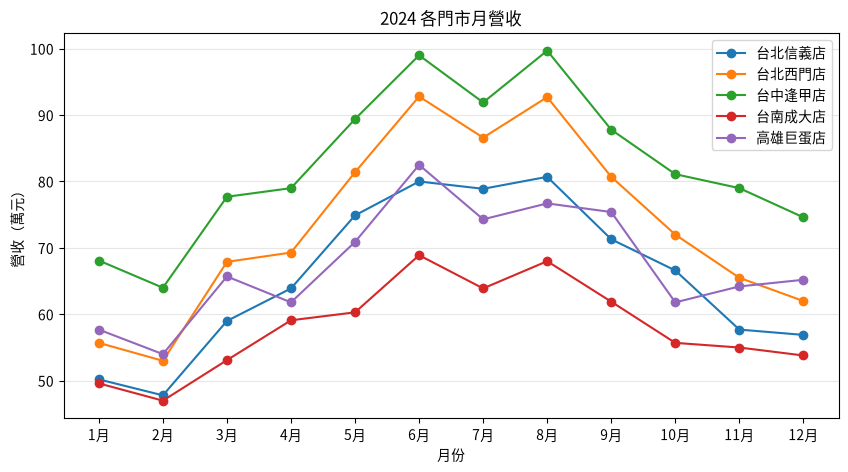

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

monthly = pd.read_csv('門市月營收_2024.csv', index_col='月份')   # 讀取月營收，月份當索引
print(monthly.head(3))

fig, ax = plt.subplots(figsize=(10, 5))                        # 建立畫布與畫框
for store in monthly.columns:                                  # 每家店畫一條線
    ax.plot(monthly.index, monthly[store], marker='o', label=store)
ax.set_title('2024 各門市月營收')                               # 標題
ax.set_xlabel('月份')
ax.set_ylabel('營收（萬元）')
ax.grid(axis='y', alpha=0.3)                                   # 淡淡的水平格線
ax.legend()                                                    # 圖例
plt.show()

> 💡 **看懂結果**：五條線都是「夏天高、冬天低」——天氣熱，飲料就好賣。台中逢甲店整年都是第一名；7 月雖然最熱，但遇到凱米颱風停班停課，成長被打斷了一下。
>
> 🤖 **換你問 AI**：「請用 matplotlib 畫 5 家門市 12 個月營收的折線圖，每家店一條線加圓點，標題『2024 各門市月營收』，並設定繁體中文字型。」

## 圖 2：什麼最好賣？——排序長條圖＋數值標註

**老闆的問題**：「十個品項裡，哪幾杯是台柱？哪幾杯可以考慮下架？」

**白話說明**：「比較大小」用長條圖。品項名稱很長時，用**水平長條**（`barh`）比較好讀；排序後再標上數字，簡報時一目了然。

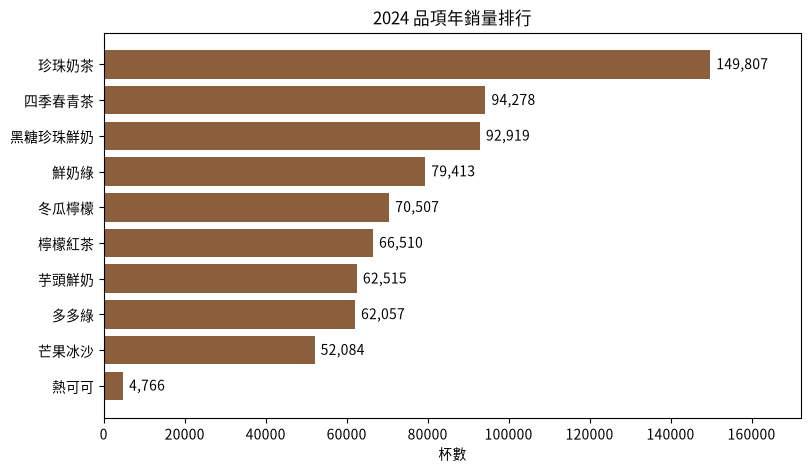

In [4]:
items = pd.read_csv('品項年銷量_2024.csv', index_col='品項')['年銷量(杯)'].sort_values()   # 由小到大排序（畫水平長條時最大的會在最上面）

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(items.index, items.values, color='#8B5E3C')     # 水平長條圖，奶茶色
for bar, v in zip(bars, items.values):                         # 在每根長條右邊標上數字
    ax.text(v + 1500, bar.get_y() + bar.get_height() / 2, f'{v:,}', va='center')
ax.set_title('2024 品項年銷量排行')
ax.set_xlabel('杯數')
ax.set_xlim(0, items.max() * 1.15)                             # 右邊留空間放數字
plt.show()

> 💡 **看懂結果**：珍珠奶茶遙遙領先，是品牌的台柱。4 月才上市的芋頭鮮奶全年總量看起來不高，但它只賣了 9 個月——換算成「每月平均」就一點也不輸老品項（練習時可以算算看）。熱可可只有冬天賣，總量最少，但它是冬天的重要商品。**比較之前，先確認大家的基準（期間）是否一致。**
>
> 🤖 **換你問 AI**：「請把這份品項銷量畫成由大到小的水平長條圖，長條右側標上千分位數字。」

## 圖 3：我們的客人是誰？——直方圖看分布

**老闆的問題**：「會員大概幾歲？行銷活動要針對誰？」

**白話說明**：想知道「數字集中在哪個範圍」用直方圖：把年齡切成一格一格的區間，數每一格有幾個人。

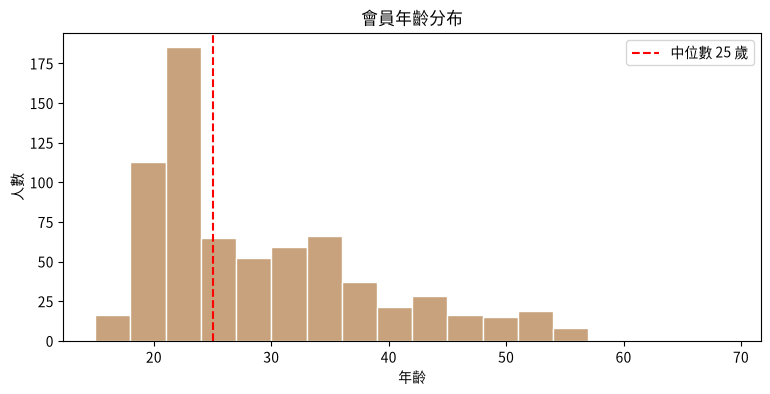

In [5]:
ages = pd.read_csv('會員年齡.csv')['年齡']

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(ages, bins=range(15, 72, 3), color='#C8A27C', edgecolor='white')   # 每 3 歲一個區間
ax.axvline(ages.median(), color='red', linestyle='--', label=f'中位數 {ages.median():.0f} 歲')  # 畫一條中位數參考線
ax.set_title('會員年齡分布')
ax.set_xlabel('年齡')
ax.set_ylabel('人數')
ax.legend()
plt.show()

> 💡 **看懂結果**：分布有**兩座山**：20 歲出頭的大學生，和 30 歲左右的上班族。只看「平均年齡」會得到一個兩邊都不像的數字——這就是為什麼一定要畫圖看分布。

## 圖 4：大家都喝幾分糖？——圓餅圖看比例

**老闆的問題**：「要不要推『微糖、無糖』的健康系列？」

**白話說明**：「各部分佔整體幾成」用圓餅圖。類別不要超過 5～6 個，太多就改用長條圖。

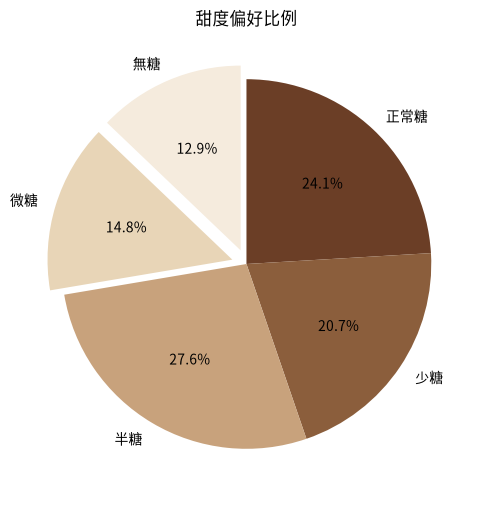

In [6]:
sweet = pd.read_csv('甜度偏好_2024.csv', index_col='甜度')['杯數']

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(sweet.values, labels=sweet.index,
       autopct='%1.1f%%',                                      # 自動顯示百分比
       startangle=90, counterclock=False,                      # 從 12 點鐘方向順時針排列
       explode=[0, 0, 0, 0.08, 0.08],                          # 把微糖、無糖往外拉，強調健康系列
       colors=['#6B3E26', '#8B5E3C', '#C8A27C', '#E8D5B7', '#F5EBDD'])
ax.set_title('甜度偏好比例')
plt.show()

> 💡 **看懂結果**：微糖加無糖接近三成，是不小的族群——推出健康系列有市場。

## 圖 5：天氣越熱，冰沙越好賣嗎？——散佈圖看關係

**老闆的問題**：「芒果冰沙跟熱可可要備多少料，可以看天氣決定嗎？」

**白話說明**：想看「兩個數字有沒有關係」用散佈圖：每一天是一個點，X 是氣溫，Y 是杯數。

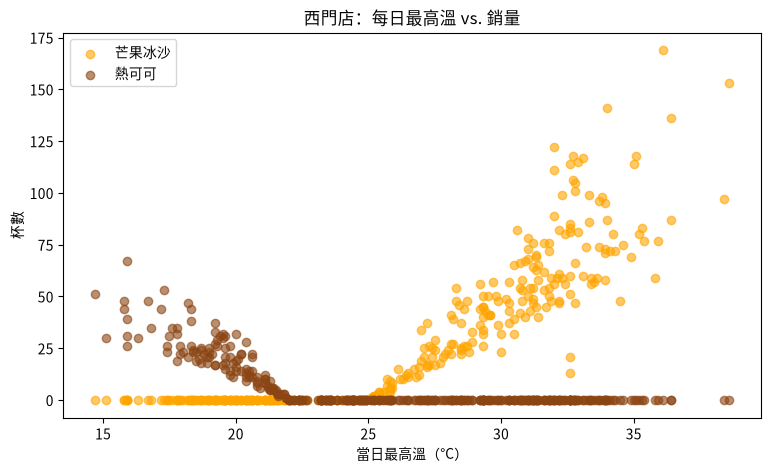

In [7]:
daily = pd.read_csv('西門店每日氣溫與銷量_2024.csv')

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(daily['最高溫'], daily['芒果冰沙'], alpha=0.6, label='芒果冰沙', color='orange')
ax.scatter(daily['最高溫'], daily['熱可可'], alpha=0.6, label='熱可可', color='saddlebrown')
ax.set_title('西門店：每日最高溫 vs. 銷量')
ax.set_xlabel('當日最高溫（°C）')
ax.set_ylabel('杯數')
ax.legend()
plt.show()

> 💡 **看懂結果**：兩種飲料剛好是「交叉」的——超過 25 度冰沙開始大賣、越熱賣越多；低於 22 度熱可可才有人買。**看氣象預報備料**，就能減少浪費、避免缺貨。
>
> 🤖 **換你問 AI**：「請用散佈圖呈現每日最高溫與芒果冰沙杯數的關係，並加上一條趨勢線，用白話解釋結果。」

## 最後一步：組成一頁儀表板並存檔

**白話說明**：用 `plt.subplots(2, 2)` 在一張畫布上放四張圖，再用 `savefig` 存成高解析度圖片，直接貼進簡報。

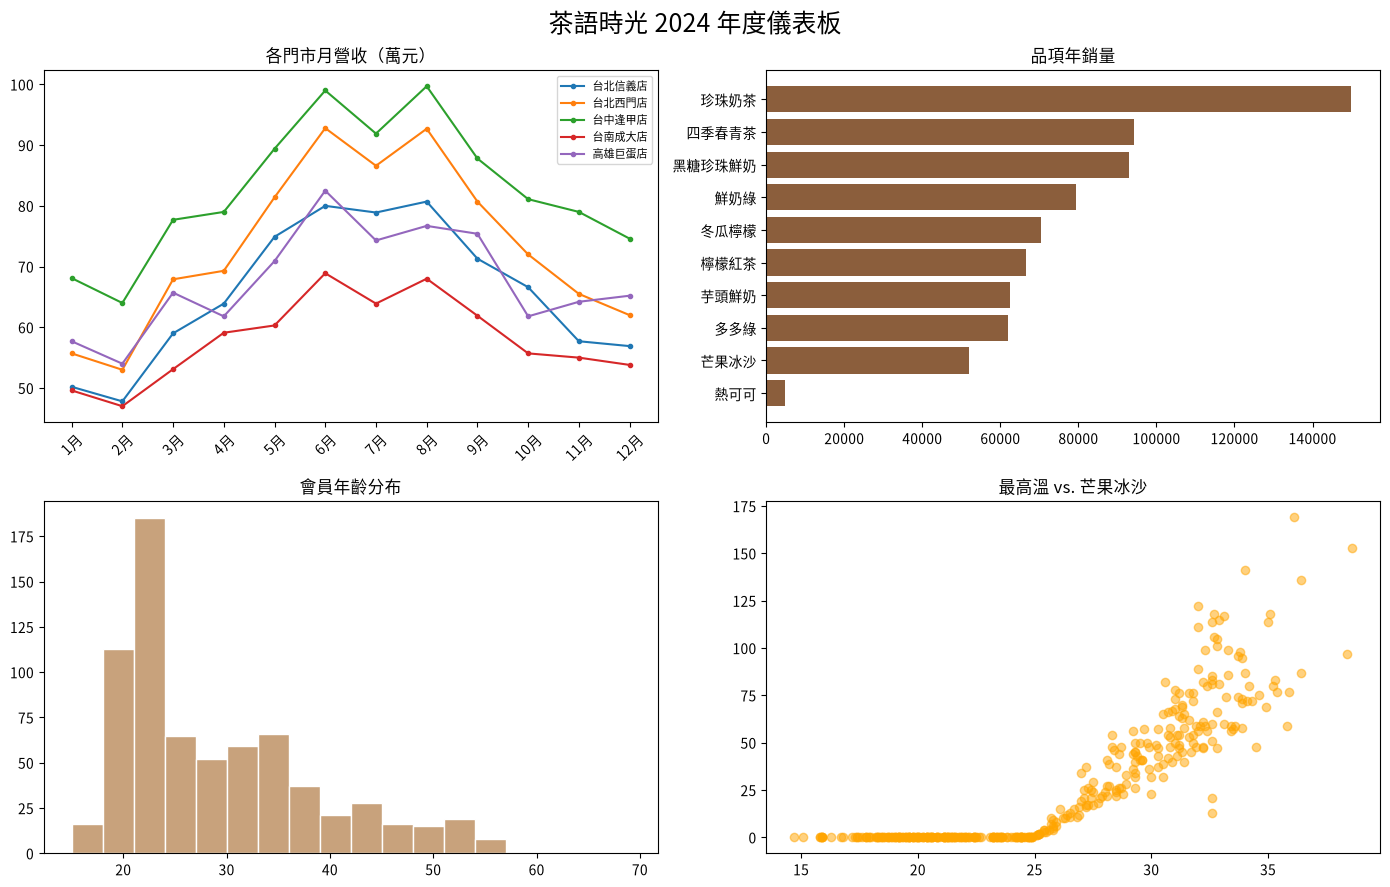

已存成 2024年度儀表板.png


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for store in monthly.columns:                                          # 左上：月營收
    axes[0, 0].plot(monthly.index, monthly[store], marker='.', label=store)
axes[0, 0].set_title('各門市月營收（萬元）')
axes[0, 0].legend(fontsize=8)
axes[0, 0].tick_params(axis='x', rotation=45)

axes[0, 1].barh(items.index, items.values, color='#8B5E3C')            # 右上：品項銷量
axes[0, 1].set_title('品項年銷量')

axes[1, 0].hist(ages, bins=range(15, 72, 3), color='#C8A27C', edgecolor='white')   # 左下：年齡
axes[1, 0].set_title('會員年齡分布')

axes[1, 1].scatter(daily['最高溫'], daily['芒果冰沙'], alpha=0.5, color='orange')   # 右下：氣溫 vs 冰沙
axes[1, 1].set_title('最高溫 vs. 芒果冰沙')

fig.suptitle('茶語時光 2024 年度儀表板', fontsize=18)
plt.tight_layout()
plt.savefig('2024年度儀表板.png', dpi=200, bbox_inches='tight')        # 存成高解析度圖片
plt.show()
print('已存成 2024年度儀表板.png')

---

## ✍️ 換你動手：練習區

每一題都有三格：**① 半成品程式**（把 `___` 換成正確的程式）→ **② ✅ 檢查格**（自動告訴你對不對）→ **③ 🔑 參考解答**（折疊起來，先自己試）。

> 看到 `NameError: name '___' is not defined` 不用緊張，那代表還有空格沒填。

In [9]:
# @title 🧰 練習檢查小幫手（執行一次就好，不用看懂裡面的程式）
import math
import numpy as np
import pandas as pd


def _same(ans, expected, ordered=False):
    if isinstance(expected, (pd.DataFrame, pd.Series)):
        if type(ans) is not type(expected):
            return False
        try:
            assert_equal = pd.testing.assert_frame_equal if isinstance(expected, pd.DataFrame) else pd.testing.assert_series_equal
            if not ordered:
                ans, expected = ans.sort_index(), expected.sort_index()
            assert_equal(ans, expected, check_names=False, check_dtype=False,
                         check_index_type=False, check_exact=False, rtol=1e-3, atol=0.06,
                         **({'check_column_type': False} if isinstance(expected, pd.DataFrame) else {}))
            return True
        except (AssertionError, TypeError, ValueError):
            return False
    if isinstance(expected, np.ndarray):
        return np.asarray(ans).shape == expected.shape and np.allclose(np.asarray(ans, dtype=float), expected, atol=0.06)
    if isinstance(expected, (int, float, np.number)) and not isinstance(expected, bool):
        try:
            return math.isclose(float(ans), float(expected), rel_tol=1e-3, abs_tol=0.06)
        except (TypeError, ValueError):
            return False
    if isinstance(expected, (list, tuple, set)):
        return list(ans) == list(expected) if not isinstance(expected, set) else set(ans) == expected
    return ans == expected


def check(name, expected, ordered=False):
    """比對學生的變數 name 和正確答案 expected，印出 ✅ 或 ❌；ordered=True 時連排列順序也要一樣。"""
    if name not in globals():
        print(f'⏳ 還找不到變數 {name}：請先把上一格的 ___ 填好並執行')
        return
    ans = globals()[name]
    if _same(ans, expected, ordered):
        print(f'✅ {name} 答對了！')
        return
    print(f'❌ {name} 還不對，再檢查看看：')
    if type(ans) is not type(expected):
        print(f'   型態不同：你的是 {type(ans).__name__}，應該是 {type(expected).__name__}')
    elif hasattr(expected, 'shape') and getattr(ans, 'shape', None) != expected.shape:
        print(f'   大小不同：你的是 {ans.shape}，應該是 {expected.shape}')
    else:
        print('   型態和大小都對了，是數值' + ('或排列順序' if ordered else '') + '不一樣——檢查一下篩選條件或計算方式')


print('🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格')

🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格


### ✍️ 練習 1：只畫「台南成大店」的月營收，並在最高的月份標上「全年最高」

<details><summary>💡 卡住了？點我看提示</summary>

`monthly` 的每一欄是一家門市；`s.idxmax()` 會告訴你「最大值在哪一個索引（月份）」。

</details>

In [ ]:
# ✏️ 練習 1：把 ___ 換成正確的程式，再按執行
s = monthly[___]                                   # 取出台南成大店這一欄
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(s.index, s.values, marker='o', color='#8B5E3C')
best = s.___()                                     # 營收最高的月份
ax.annotate('全年最高', xy=(best, s[best]), xytext=(best, s[best] + 3),
            ha='center', arrowprops=dict(arrowstyle='->'))
ax.set_title('台南成大店月營收（萬元）')
plt.show()

In [ ]:
# @title ✅ 執行這格，檢查練習 1
check('best', monthly['台南成大店'].idxmax())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
s = monthly['台南成大店']
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(s.index, s.values, marker='o', color='#8B5E3C')
best = s.idxmax()
ax.annotate('全年最高', xy=(best, s[best]), xytext=(best, s[best] + 3),
            ha='center', arrowprops=dict(arrowstyle='->'))
ax.set_title('台南成大店月營收（萬元）')
plt.show()
```

</details>

### ✍️ 練習 2：天氣越熱，生意越好嗎？畫出西門店「最高溫 vs. 總杯數」散佈圖

<details><summary>💡 卡住了？點我看提示</summary>

看「兩個數字之間的關係」用散佈圖：`ax.scatter(x, y)`。畫好後問自己：點是不是往右上方走？

</details>

In [ ]:
# ✏️ 練習 2：把 ___ 換成正確的程式，再按執行
fig, ax = plt.subplots(figsize=(8, 4))
ax.___(daily['最高溫'], daily['總杯數'], alpha=0.5)   # 哪一種圖適合看兩個數字的關係？
ax.set_xlabel('最高溫'); ax.set_ylabel('總杯數'); ax.set_title('西門店：氣溫 vs. 總杯數')
plt.show()

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(daily['最高溫'], daily['總杯數'], alpha=0.5)
ax.set_xlabel('最高溫'); ax.set_ylabel('總杯數'); ax.set_title('西門店：氣溫 vs. 總杯數')
plt.show()
```

</details>

### ✍️ 練習 3：把品項銷量改成直立長條圖：由大到小排序、X 軸文字轉 45 度

<details><summary>💡 卡住了？點我看提示</summary>

`sort_values(ascending=False)` 是由大到小；直立長條是 `ax.bar`；旋轉文字用 `ax.tick_params(axis='x', rotation=45)`。

</details>

In [ ]:
# ✏️ 練習 3：把 ___ 換成正確的程式，再按執行
top = items.sort_values(ascending=___)             # 由大到小
fig, ax = plt.subplots(figsize=(9, 4))
ax.___(top.index, top.values, color='#C8A27C')     # 直立長條圖
ax.tick_params(axis='x', rotation=___)
ax.set_title('品項年銷量')
plt.show()

In [ ]:
# @title ✅ 執行這格，檢查練習 3
check('top', items.sort_values(ascending=False), ordered=True)

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
top = items.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(top.index, top.values, color='#C8A27C')
ax.tick_params(axis='x', rotation=45)
ax.set_title('品項年銷量')
plt.show()
```

</details>